# Compare AT3D retrieved cloud volume extinction coefficient to CAMP2Ex insitu measured

In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval
plt.style.use('seaborn-v0_8-paper')

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

In [4]:
# ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.copy(deep=True).isel(z=slice(4, 12))
# ext = ext > 0.3
# ext.plot(x='x', y='y', col='z', col_wrap=4, cmap='gray')

In [5]:
at3d_cloud = r.solvers_retrieval[0.67].medium['cloud'].extinction.to_dataframe()
at3d_cloud = at3d_cloud[at3d_cloud['extinction'] > 0.3]
at3d_cloud = at3d_cloud.reset_index()
at3d_cloud['x'] *= 1000
at3d_cloud['y'] *= 1000
at3d_cloud['z'] *= 1000
at3d_cloud['source'] = 'AT3D'

In [6]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')
p3['source'] = 'P3'
p3['sample_optical_path'] = p3['ext_km'] * p3['Length_m'] * 1e-3

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:108: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


In [7]:
# The sample at time t is part of the cloud element e if
# the extinction at time t > 0.3 
# and there is another sample t' \in e such that |t-t'| < 3
# In other words, it takes 3 seconds of clear air to separate two clouds
ext_th = 0.3
t_th = pd.Timedelta(3, 's')
p3['cloud_pass'] = -1
cloud_pass = 1
inCloud = False
t_last_cloud = p3.index[0]
for row in p3.itertuples():
    if(not inCloud):
        if(row.ext_km > ext_th):
            inCloud = True
            t_last_cloud = row.Index
            p3.at[row.Index, 'cloud_pass'] = cloud_pass
    else:
        if(row.ext_km > ext_th):
            t_last_cloud = row.Index
            p3.at[row.Index, 'cloud_pass'] = cloud_pass
        elif(row.Index - t_last_cloud < t_th):
            p3.at[row.Index, 'cloud_pass'] = cloud_pass
        else:
            p3.loc[t_last_cloud+pd.Timedelta(1, 's'):row.Index, 'cloud_pass'] = -1
            inCloud = False
            cloud_pass += 1

g = p3.groupby('cloud_pass')['sample_optical_path']
p3['forward_optical_path'] = g.cumsum()
p3['backward_optical_path'] = g.apply(lambda s: s[::-1].cumsum()[::-1]).reset_index(level=0, drop=True)
p3['optical_path'] = p3[['forward_optical_path', 'backward_optical_path']].min(axis=1)
p3['pass_length'] = p3.groupby('cloud_pass')['Length_m'].transform('sum')

/tmp/ipykernel_1953367/1373545885.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p3['cloud_pass'] = -1
/tmp/ipykernel_1953367/1373545885.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p3['forward_optical_path'] = g.cumsum()
/tmp/ipykernel_1953367/1373545885.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfra

In [8]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

bins = np.arange(350, 1251, 100)
p3['altitude_bin'] = pd.cut(p3['GPS_Altitude'], bins=bins)
at3d_cloud['altitude_bin'] = pd.cut(at3d_cloud['z'], bins=bins)

p3_subset = p3[
    # (p3['N_L'] > 10000)
    (p3['ext_km'] > 0.3)
    & (p3.index > start_time)
    & (p3.index < end_time)
    & (p3['GPS_Altitude'] < 1250)
    & (p3['optical_path'] < 5)
    # & (p3['pass_length'] < 3600)
]

/tmp/ipykernel_1953367/2834277220.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  p3['altitude_bin'] = pd.cut(p3['GPS_Altitude'], bins=bins)


In [9]:
p3_subset['Ground_Speed'].mean()

116.67174825174824

<Axes: xlabel='ext_km', ylabel='GPS_Altitude'>

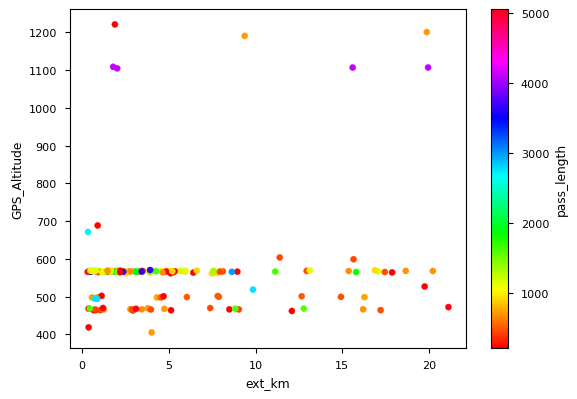

In [10]:
p3_subset.plot.scatter(x='ext_km', y='GPS_Altitude', c='pass_length', cmap='hsv')

<Axes: xlabel='ext_km', ylabel='GPS_Altitude'>

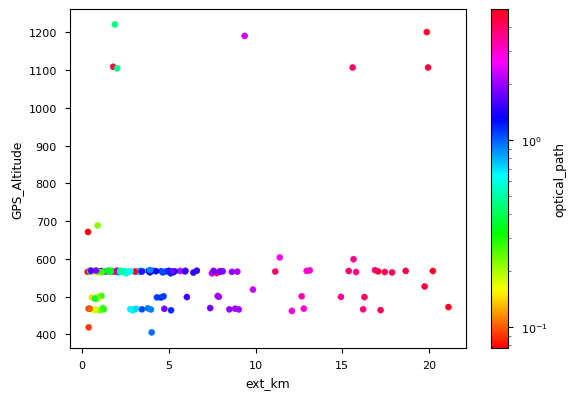

In [11]:
p3_subset.plot.scatter(x='ext_km', y='GPS_Altitude', c='optical_path', norm='log', cmap='hsv')

In [12]:
# p3_subset[p3_subset['optical_path'] < 5].plot.scatter(x='ext_km', y='GPS_Altitude', c='optical_path', norm='log', cmap='CMRmap')

In [13]:
p3_agg = p3_subset.reset_index().groupby('cloud_pass').agg(
    start_time=('datetime', 'min'),
    end_time=('datetime', 'max'),
    alt_min=('GPS_Altitude', 'min'),
    alt_max=('GPS_Altitude', 'max'),
    pass_length=('Length_m', 'sum'),
    alt_bin=('altitude_bin', 'max'),
    sum_ext = ('ext_km', 'sum'),
    max_optical_path = ('optical_path', 'max')
)
p3_agg['optical_depth'] = p3_agg['sum_ext'] * p3_agg['pass_length'] * 1e-3
# p3_agg

<Axes: xlabel='extinction', ylabel='altitude_bin'>

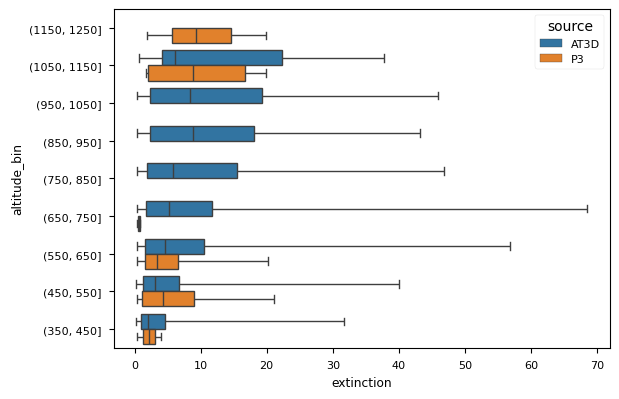

In [14]:
tmp_at3d_cloud = at3d_cloud.loc[:, ['extinction', 'altitude_bin', 'source']]
tmp_p3 = p3_subset.reset_index().loc[:, ['ext_km', 'altitude_bin', 'source']].rename(columns={'ext_km':'extinction'})
tmp_merged = pd.concat([tmp_at3d_cloud, tmp_p3])
order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sns.boxplot(tmp_merged, x='extinction', y='altitude_bin', hue='source', order=order, whis=(0,100))
# sns.violinplot(tmp_merged, x='extinction', y='altitude_bin', hue='source', split=True, cut=0, inner='quart', order=order)

In [15]:
rows = []
for i in range(len(bins) - 1):
    level = pd.Interval(left=bins[i], right=bins[i+1], closed='right')
    at3d_ext = at3d_cloud.loc[at3d_cloud['altitude_bin'] == level, 'extinction']
    p3_ext = p3_subset.loc[p3_subset['altitude_bin'] == level, 'ext_km']
    if((len(at3d_ext) > 0) & (len(p3_ext) > 0)):
        result = stats.kstest(at3d_ext, p3_ext)
        row = {
            'level': level,
            'statistic': result.statistic,
            'pvalue': result.pvalue,
            'statistic_location': result.statistic_location,
            'statistic_sign': result.statistic_sign,
            'N_at3d': len(at3d_ext),
            'N_p3': len(p3_ext)
        }
        rows.append(row)
ks_stats = pd.DataFrame(rows, columns=[n for n in row])
ks_stats


,level,statistic,pvalue,statistic_location,statistic_sign,N_at3d,N_p3
0,"(350, 450]",0.450904,0.681645,0.380726,-1,387,2
1,"(450, 550]",0.163854,0.209110,2.773769,1,547,43
2,"(550, 650]",0.171896,0.018984,5.960282,-1,539,89
3,"(650, 750]",0.872792,0.034742,0.902081,-1,283,2
4,"(1050, 1150]",0.441176,0.454470,2.025236,-1,17,4


In [16]:
rows = []
for i in range(len(bins) - 1):
    level = pd.Interval(left=bins[i], right=bins[i+1], closed='right')
    at3d_ext = at3d_cloud.loc[at3d_cloud['altitude_bin'] == level, 'extinction']
    p3_ext = p3_subset.loc[p3_subset['altitude_bin'] == level, 'ext_km']
    if((len(at3d_ext) > 0) & (len(p3_ext) > 0)):
        result = stats.kstest(at3d_ext, p3_ext, alternative='less')
        row = {
            'level': level,
            'statistic': result.statistic,
            'pvalue': result.pvalue,
            'statistic_location': result.statistic_location,
            'statistic_sign': result.statistic_sign,
            'N_at3d': len(at3d_ext),
            'N_p3': len(p3_ext)
        }
        rows.append(row)
ks_stats = pd.DataFrame(rows, columns=[n for n in row])
ks_stats


,level,statistic,pvalue,statistic_location,statistic_sign,N_at3d,N_p3
0,"(350, 450]",0.450904,0.348382,0.380726,-1,387,2
1,"(450, 550]",0.051869,0.777857,1.252493,-1,547,43
2,"(550, 650]",0.171896,0.009492,5.960282,-1,539,89
3,"(650, 750]",0.872792,0.017371,0.902081,-1,283,2
4,"(1050, 1150]",0.441176,0.228404,2.025236,-1,17,4


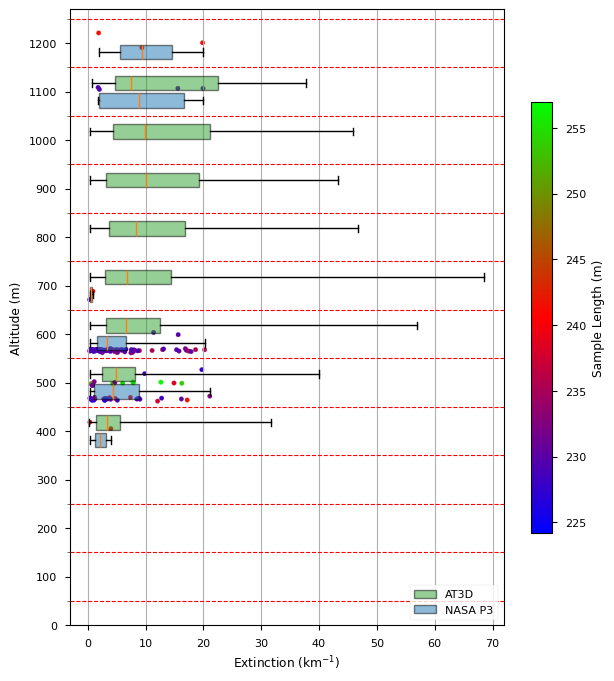

In [17]:
bins = np.arange(350, 1251, 100)

cloud = retrieval.threshold_cloud(r.solvers_retrieval[0.67].medium['cloud'], extinction_th=[0.3, np.inf], tau_th=[0.3, np.inf])
at3d_ext_box = []
for i in range(len(bins)-1):
    tmp_cloud = cloud.sel(z=slice(1e-3*bins[i], 1e-3*bins[i+1]))
    ext = tmp_cloud.extinction.data
    at3d_ext_box.append(ext[tmp_cloud.cloud_volume_mask.data==1])

p3_ext_box = []
for i in range(len(bins)-1):
    tmp = p3_subset.loc[
        (p3_subset['GPS_Altitude'] >= bins[i])
        & (p3_subset['GPS_Altitude'] < bins[i+1])
    ]['ext_km'].to_numpy()
    p3_ext_box.append(tmp)

box_kwargs = {
    'vert':False,
    'manage_ticks':False,
    'patch_artist':True,
    'widths':30,
    'whis':(0,100)
}

f, ax = plt.subplots(1, 1, figsize=(7, 8))
at3d_bplot = ax.boxplot(at3d_ext_box, positions=bins[:-1]+68, **box_kwargs)
for patch in at3d_bplot['boxes']:
    patch.set_facecolor('tab:green')
    patch.set_alpha(0.5)

p3_bplot = ax.boxplot(p3_ext_box, positions=bins[:-1]+32, **box_kwargs)
for patch in p3_bplot['boxes']:
    patch.set_facecolor('tab:blue')
    patch.set_alpha(0.5)

scat_kwargs = {'s':10, 'cmap':'brg'}
p3_dots = ax.scatter(p3_subset['ext_km'], p3_subset['GPS_Altitude'], c=p3_subset['Length_m'], **scat_kwargs)
plt.colorbar(p3_dots, ax=ax, label='Sample Length (m)', shrink=0.7)

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
ax.grid(visible=True, which='major', axis='x')
ax.grid(visible=True, which='minor', axis='y', color='r', linestyle='--')

ax.set_yticks(np.arange(0, 1400, 100))
ax.set_yticks(np.arange(50, 1300, 100), minor=True)
ax.set_ylim([0, 1270])
ax.set_xlabel(r'Extinction (km$^{-1}$)')

ax.legend([at3d_bplot['boxes'][0], p3_bplot['boxes'][0]], ['AT3D', 'NASA P3'], loc='lower right')